<a href="https://colab.research.google.com/github/adityarizqiqa/PCVK_Ganjil2026/blob/main/week09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

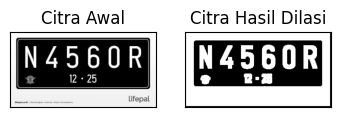

In [3]:
# Dilasi tanpa library
def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

[[1 1 1]
 [1 1 1]
 [1 1 1]]


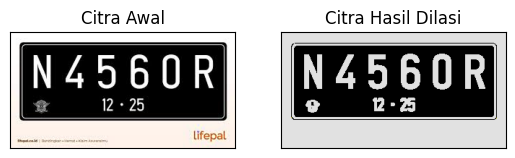

In [4]:
img = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg')
# img = cv2.imread('morp.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint16)
dilasi = cv2.dilate(thresh, kernel, iterations=1)
print(kernel)

plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(dilasi), plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

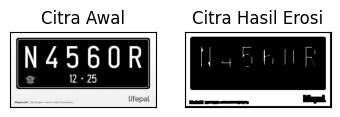

In [5]:
# Erosi Tanpa Library
def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

img_e = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

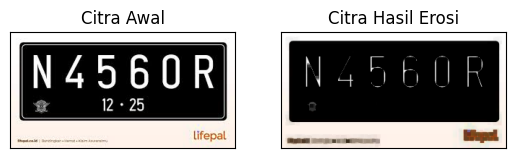

In [6]:
# EROSI LIBRARY
img = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg')
kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

plt.subplot(121), plt.imshow(img), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(erosion), plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()

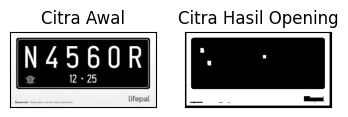

In [7]:
# Operasi Opening Tanpa Library Morphology
img_o = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k = 7
imgO = dilasi_citra(erosi_citra(thresho, k), k)

plt.subplot(131), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgO, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

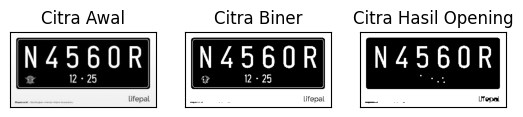

In [8]:
# Dengan Menggunakan Library
img = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

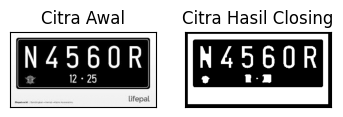

In [9]:
# Operasi Closing Tanpa Library Morphology
img_c = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k = 7
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.subplot(131), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

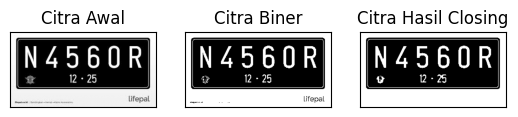

In [10]:
# Operasi Closing Dengan Library Morphology
img = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Cross 3


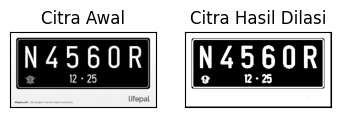

SED = Cross 5


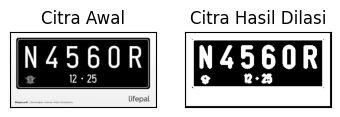

In [11]:
# Dilasi Cross SED 3x3
def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    # Generate structure element dilasi (SED) Cross 3x3
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 3')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

# Dilasi Cross SED 5x5
def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    # Generate structure element dilasi (SED) Cross 5x5
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Cross 5')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SED = Circle 3


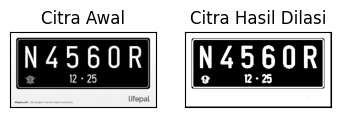

SED = Circle 5


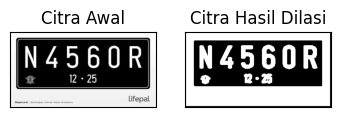

In [12]:
# Dilasi Circular SED
def dilasi_citra(F, w):
    # size image
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate structure element dilasi (SED)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

print('SED = Circle 3')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 3
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SED = Circle 5')
img_d = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Rectangle 3x5


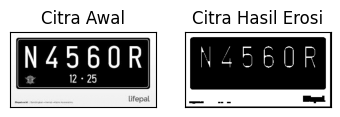

SE = Rectangle 5x7


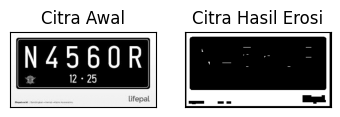

In [13]:
# Erosi Rectangle SE
def erosi_citra(F, p, l):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l)) # SE persegi panjang
    constant1 = (l - 1) // 2
    constant2 = (p - 1) // 2
    # print(SE)
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1:i + constant1 + 1, j - constant2:j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

print('SE = Rectangle 3x5')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 5
l = 3
imgE = erosi_citra(thresh1, p, l)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Rectangle 5x7')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p = 7
l = 5
imgE = erosi_citra(thresh1, p, l)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

SE = Line Vertikal 3


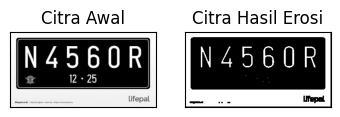

SE = Line Vertikal 5


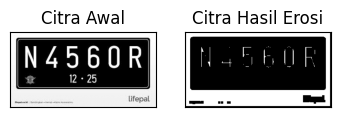

In [14]:
# Erosi Line Vertikal SE
def erosi_citra(F, k):
    # size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k)) # SE line vertikal
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)
    return imgE

print('SE = Line Vertikal 3')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 3
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Line Vertikal 5')
img_e = cv2.imread('/content/drive/MyDrive/PCVK/plat nomer.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k = 5
imgE = erosi_citra(thresh1, k)

plt.subplot(131), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

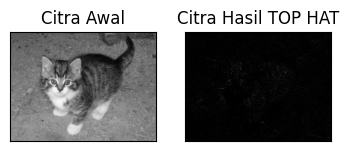

In [15]:
# 13. TopHat
# Getting the kernel to be used in Top-Hat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image
img = cv2.imread('/content/drive/MyDrive/PCVK/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(img, cv2.MORPH_TOPHAT, kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(tophat_img, cmap='gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()

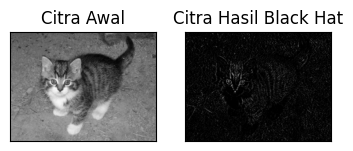

In [16]:
# 14. BLACKHAT
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'kitten01.jpg'
img = cv2.imread('/content/drive/MyDrive/PCVK/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(blackhat, cmap='gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()

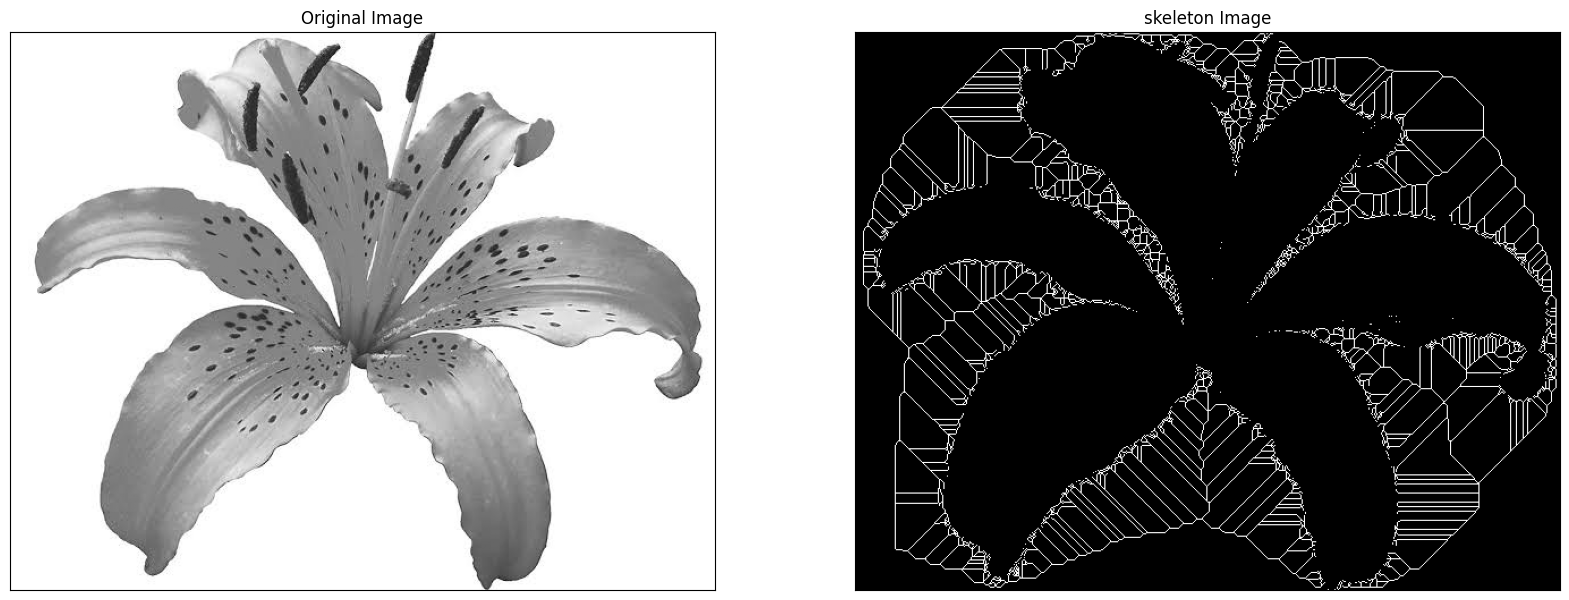

In [17]:
# 15. Skeleton
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv.imread('/content/drive/MyDrive/PCVK/lily.jpg', 0)
binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20, 20))
plt.subplot(121), plt.imshow(img, cmap='gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig("binary and bin_skeleton.png")
plt.show()

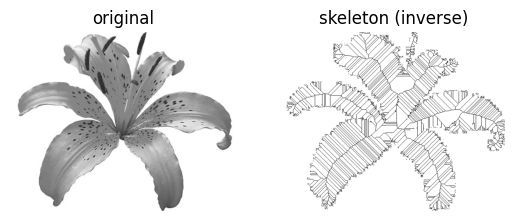

In [18]:
# 16. Skeleton Inverse
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = io.imread('/content/drive/MyDrive/PCVK/lily.jpg')[..., 0]

# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)

# skeletonize image
skeleton = skeletonize(binary)

# print images
fig, ax = plt.subplots(1, 2)
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

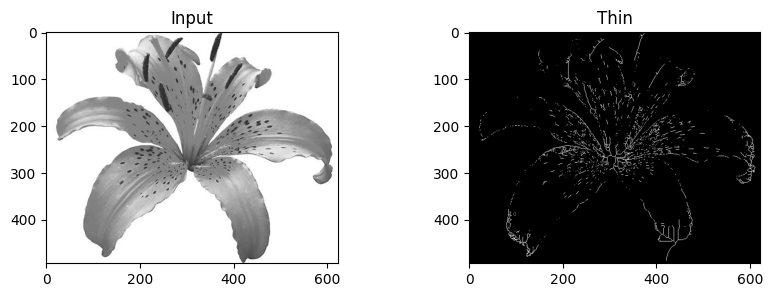

In [19]:
# 17. Thickening / Thinning
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()

Tugas Praktikum – Implementasi Morfologi pada Citra KTP

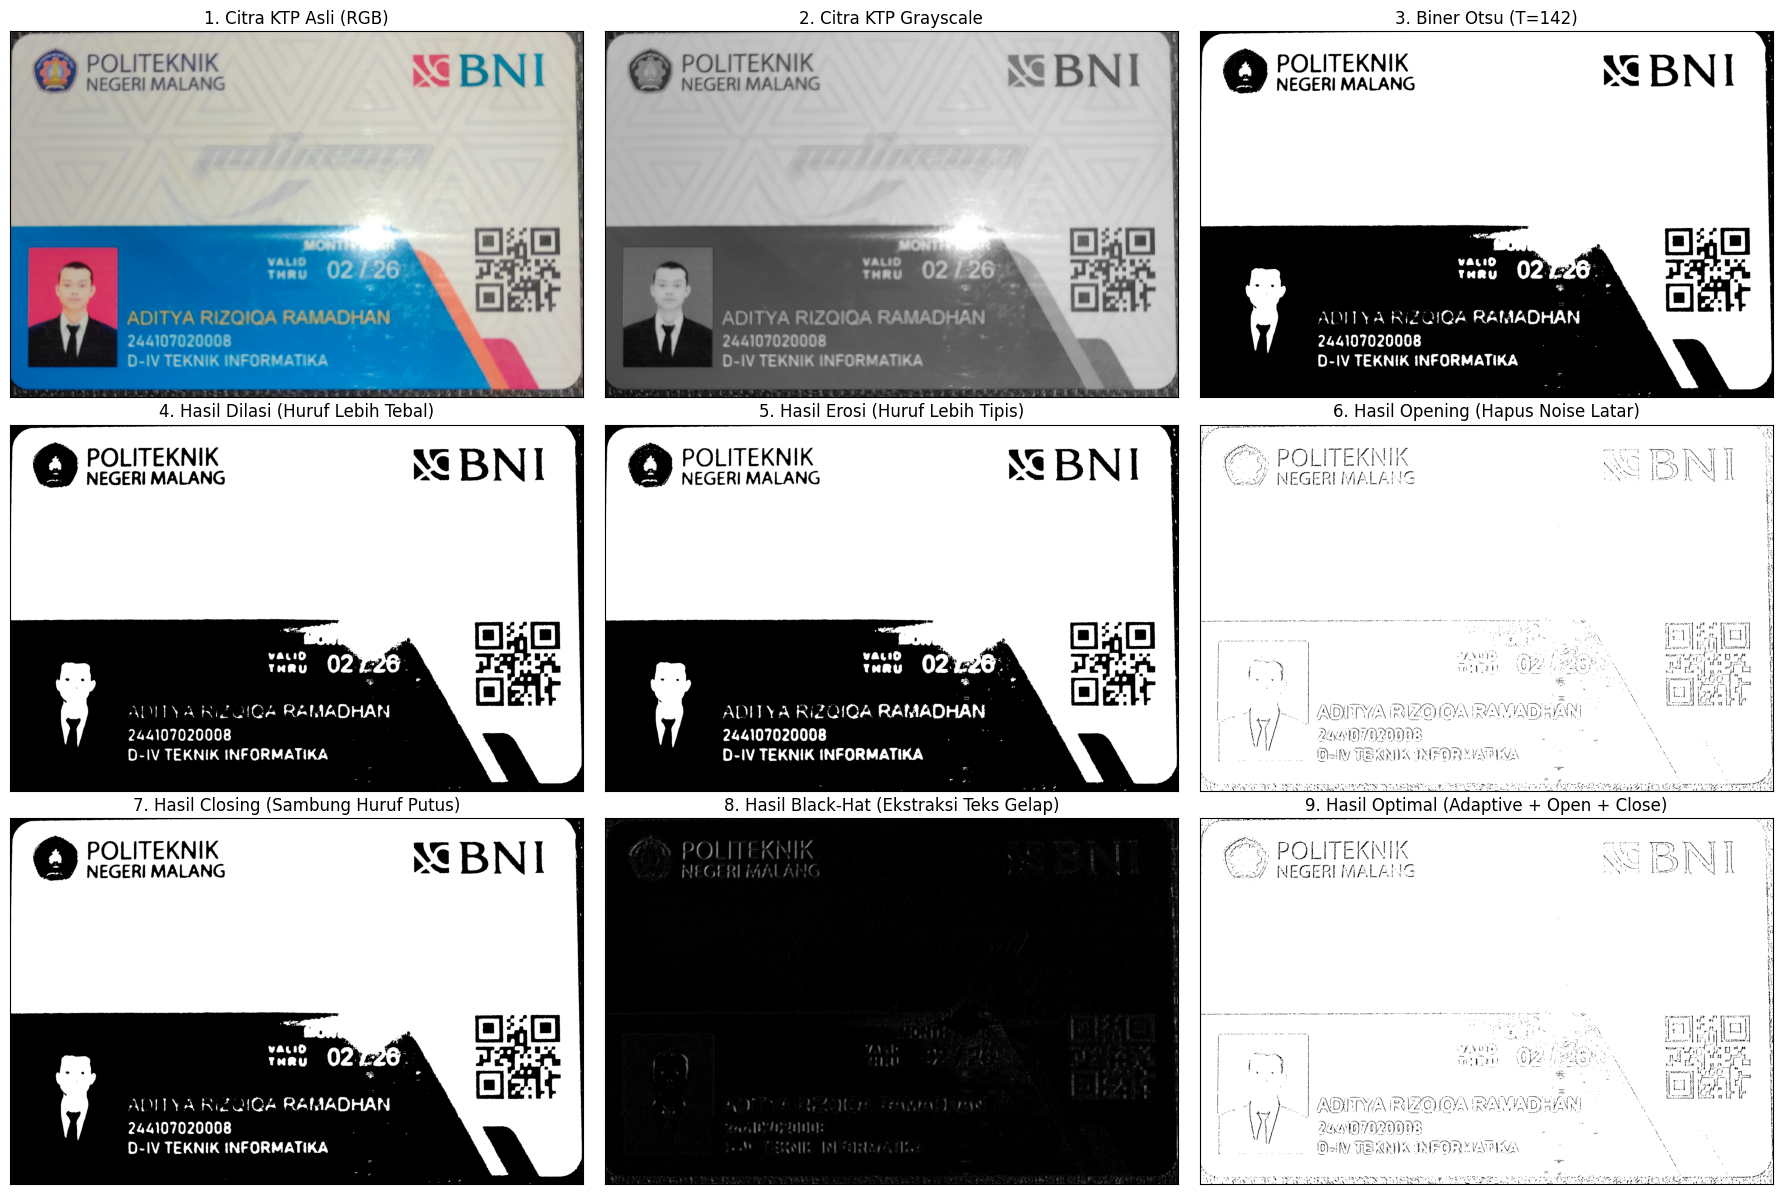

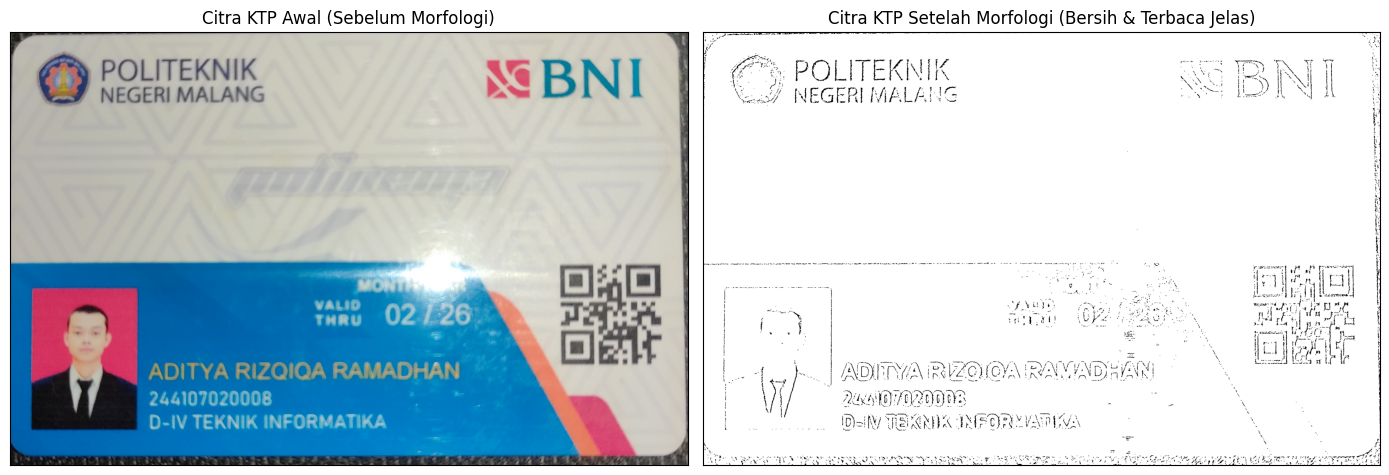

In [20]:
# ==============================================================================
# E. TUGAS PRAKTIKUM: IMPLEMENTASI OPERASI MORFOLOGI PADA CITRA KTP
# ==============================================================================
import cv2
import numpy as np
from matplotlib import pyplot as plt

# 1. Membaca Citra KTP dari Google Drive (Sesuaikan nama file dengan dataset KTP Modul 7 Anda)
ktp_path = '/content/drive/MyDrive/PCVK/KTM1a.jpeg'  # Ubah jika nama file Anda berbeda
img_ktp = cv2.imread(ktp_path)

if img_ktp is None:
    print(f"File '{ktp_path}' tidak ditemukan! Pastikan path sesuai dengan lokasi file KTP di Google Drive Anda.")
else:
    # Konversi BGR ke RGB dan Grayscale
    img_ktp_rgb = cv2.cvtColor(img_ktp, cv2.COLOR_BGR2RGB)
    gray_ktp = cv2.cvtColor(img_ktp, cv2.COLOR_BGR2GRAY)

    # 2. Binarisasi dengan Otsu & Adaptive Thresholding (Inverse: Teks = Putih 255, Latar = Hitam 0)
    ret_otsu, thresh_inv = cv2.threshold(gray_ktp, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    thresh_adapt_inv = cv2.adaptiveThreshold(
        gray_ktp, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 15, 8
    )

    # 3. Membuat Structuring Element (SE) dengan ukuran yang disesuaikan untuk teks KTP
    se_rect_2x2 = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    se_rect_3x3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    se_cross_3x3 = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))
    se_blackhat = cv2.getStructuringElement(cv2.MORPH_RECT, (15, 5))

    # 4. Menerapkan Berbagai Operasi Morfologi pada Citra KTP
    # a) Dilasi (menebalkan karakter teks KTP)
    ktp_dilasi = cv2.dilate(thresh_inv, se_rect_2x2, iterations=1)

    # b) Erosi (menipiskan karakter teks & menghilangkan bintik kecil)
    ktp_erosi = cv2.erode(thresh_inv, se_rect_2x2, iterations=1)

    # c) Opening (menghilangkan noise bintik latar belakang)
    ktp_opening = cv2.morphologyEx(thresh_adapt_inv, cv2.MORPH_OPEN, se_rect_2x2)

    # d) Closing (menyambung karakter huruf/angka yang terputus)
    ktp_closing = cv2.morphologyEx(thresh_inv, cv2.MORPH_CLOSE, se_rect_2x2)

    # e) Kombinasi Optimal (Adaptive Threshold + Opening 2x2 + Closing Cross 3x3)
    ktp_optimal_inv = cv2.morphologyEx(thresh_adapt_inv, cv2.MORPH_OPEN, se_rect_2x2)
    ktp_optimal_inv = cv2.morphologyEx(ktp_optimal_inv, cv2.MORPH_CLOSE, se_cross_3x3)

    # Inversi kembali agar ditampilkan sebagai Teks Hitam di atas Latar Putih (mudah dibaca)
    ktp_dilasi_view = cv2.bitwise_not(ktp_dilasi)
    ktp_erosi_view = cv2.bitwise_not(ktp_erosi)
    ktp_opening_view = cv2.bitwise_not(ktp_opening)
    ktp_closing_view = cv2.bitwise_not(ktp_closing)
    ktp_optimal_view = cv2.bitwise_not(ktp_optimal_inv)

    # f) Transformasi Black-Hat langsung pada citra Grayscale untuk mengekstrak teks gelap
    ktp_blackhat = cv2.morphologyEx(gray_ktp, cv2.MORPH_BLACKHAT, se_blackhat)

    # 5. Menampilkan Perbandingan Seluruh Teknik Morfologi pada Citra KTP
    plt.figure(figsize=(18, 12))

    plt.subplot(3, 3, 1), plt.imshow(img_ktp_rgb)
    plt.title('1. Citra KTP Asli (RGB)'), plt.xticks([]), plt.yticks([])

    plt.subplot(3, 3, 2), plt.imshow(gray_ktp, cmap='gray')
    plt.title('2. Citra KTP Grayscale'), plt.xticks([]), plt.yticks([])

    plt.subplot(3, 3, 3), plt.imshow(cv2.bitwise_not(thresh_inv), cmap='gray')
    plt.title(f'3. Biner Otsu (T={int(ret_otsu)})'), plt.xticks([]), plt.yticks([])

    plt.subplot(3, 3, 4), plt.imshow(ktp_dilasi_view, cmap='gray')
    plt.title('4. Hasil Dilasi (Huruf Lebih Tebal)'), plt.xticks([]), plt.yticks([])

    plt.subplot(3, 3, 5), plt.imshow(ktp_erosi_view, cmap='gray')
    plt.title('5. Hasil Erosi (Huruf Lebih Tipis)'), plt.xticks([]), plt.yticks([])

    plt.subplot(3, 3, 6), plt.imshow(ktp_opening_view, cmap='gray')
    plt.title('6. Hasil Opening (Hapus Noise Latar)'), plt.xticks([]), plt.yticks([])

    plt.subplot(3, 3, 7), plt.imshow(ktp_closing_view, cmap='gray')
    plt.title('7. Hasil Closing (Sambung Huruf Putus)'), plt.xticks([]), plt.yticks([])

    plt.subplot(3, 3, 8), plt.imshow(ktp_blackhat, cmap='gray')
    plt.title('8. Hasil Black-Hat (Ekstraksi Teks Gelap)'), plt.xticks([]), plt.yticks([])

    plt.subplot(3, 3, 9), plt.imshow(ktp_optimal_view, cmap='gray')
    plt.title('9. Hasil Optimal (Adaptive + Open + Close)'), plt.xticks([]), plt.yticks([])

    plt.tight_layout()
    plt.show()

    # 6. Menampilkan Perbandingan Akhir (Sebelum vs Sesudah Morfologi Terbaik)
    plt.figure(figsize=(14, 6))
    plt.subplot(1, 2, 1), plt.imshow(img_ktp_rgb)
    plt.title('Citra KTP Awal (Sebelum Morfologi)'), plt.xticks([]), plt.yticks([])

    plt.subplot(1, 2, 2), plt.imshow(ktp_optimal_view, cmap='gray')
    plt.title('Citra KTP Setelah Morfologi (Bersih & Terbaca Jelas)'), plt.xticks([]), plt.yticks([])
    plt.tight_layout()
    plt.show()